In [ ]:
import sqlite3
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
SQLITE_DB = Path("../reseñas/labels.db")

In [24]:
conn = sqlite3.connect(SQLITE_DB)

In [25]:
tables = conn.execute("""
        SELECT name
        FROM sqlite_schema
        WHERE type = 'table' AND name NOT GLOB 'sqlite_*'
        ORDER BY name
""").fetchall()

for t in tables:
    print(t[0])

claims
label_history
labels
reviews
skips
suggestions


In [26]:
conn.execute("SELECT * FROM claims;").fetchall()

[]

In [53]:
SQL = f"""
SELECT
    food,
    wait_time,
    service,
    price,
    experience,
    text,
    id,
    lang,
    rating as rating_original,
    source_en as original
FROM labels l
JOIN reviews r ON
l.review_id  = r.id;
"""
cursor = conn.execute(SQL)
column_names = [column[0] for column in cursor.description]
rows = cursor.fetchall()


In [55]:
labels = {}

for row in rows:
    for column, value in zip(column_names, row):
        labels[column] = labels.get(column, []) + [value]

In [56]:
dimensions = [
    "wait_time",
    "service",
    "price",
    "experience",
    "food"
]

for d in dimensions:
    # Mapeamons 'None' a -1 para marcar que no hubo mension de esa dimension
    new_values = [v if v != None else -1 for v in labels[d]]
    labels[d] = new_values


In [57]:
df = pd.DataFrame(labels)

In [60]:
df["wait_time"].value_counts()

wait_time
-1    1705
 4     136
 3     115
 2      94
 1      25
 5      25
Name: count, dtype: int64

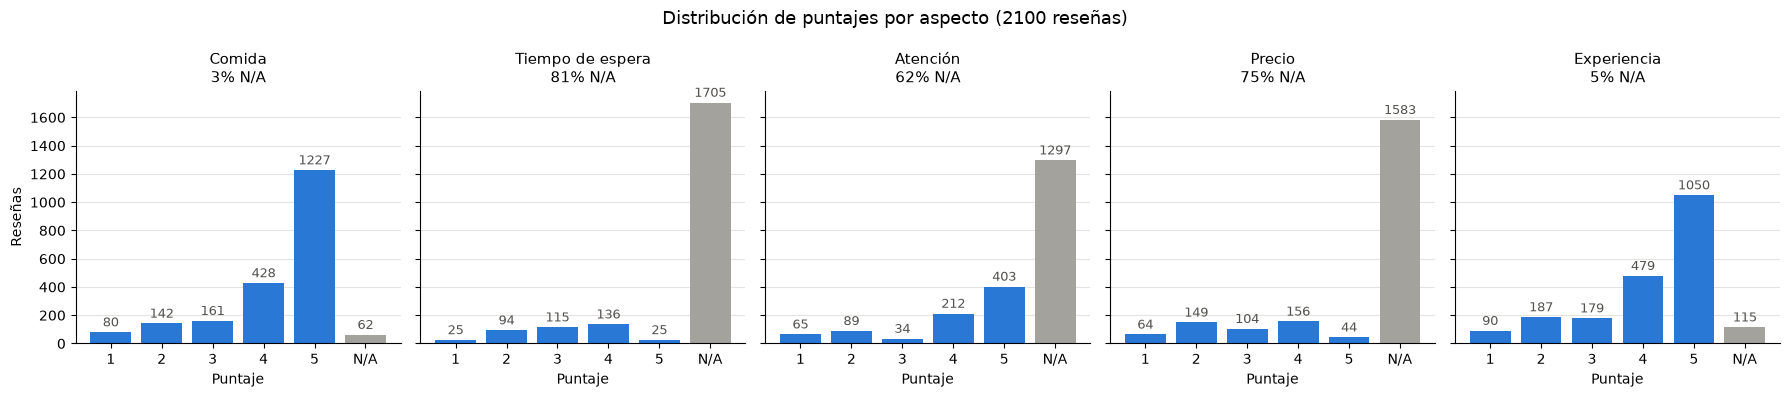

In [63]:
ASPECTS = {
    "food": "Comida",
    "wait_time": "Tiempo de espera",
    "service": "Atención",
    "price": "Precio",
    "experience": "Experiencia",
}
SCORES = [1, 2, 3, 4, 5, -1]                     # -1 = N/A (ver celda anterior)
TICKS = ["1", "2", "3", "4", "5", "N/A"]
COLORS = ["#2a78d6"] * 5 + ["#a3a29c"]           # puntajes en azul, N/A en gris

fig, axes = plt.subplots(1, len(ASPECTS), figsize=(18, 4), sharey=True)

for ax, (col, title) in zip(axes, ASPECTS.items()):
    counts = df[col].value_counts().reindex(SCORES, fill_value=0)
    bars = ax.bar(TICKS, counts.values, color=COLORS, width=0.8)
    ax.bar_label(bars, padding=2, fontsize=9, color="#52514e")
    na_pct = counts[-1] / len(df)
    ax.set_title(f"{title}\n{na_pct:.0%} N/A", fontsize=11)
    ax.set_xlabel("Puntaje")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e4e3df", linewidth=0.8)
    ax.set_axisbelow(True)

axes[0].set_ylabel("Reseñas")
fig.suptitle(f"Distribución de puntajes por aspecto ({len(df)} reseñas)", fontsize=13)
fig.tight_layout()
plt.show()

### Nota sobre N/A
Cabe destacar que 'N/A' o -1 en el df no significa dato faltante.

Es una categoria mas que indica que la review no hace mencion de ese aspecto.

Por ejemplo para el aspecto Atencion: 1297 reviews no mencionan nada sobre la atencion, esta es una caracteristica que el modelo debe aprender a observar

Entonces en el caso de una review que no menciona el aspecto atencion, se espera que el modelo le asigna una probabilidad alta a la categoria 'N/A'.

Por lo tanto tenemos 6 categorias:

1. 1-5 -> 5 categorias ordenadas donde numeros mas grandes indican mayor positividad
2. Una categoria especial 'N/A' que indica la no mencion de ese aspecto (ej: Precio), que no representa algo positivo o negativo sobre el aspecto en si, indica su ausencia.

In [ ]:
from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit

SEED = 42
VAL_SIZE, TEST_SIZE = 0.15, 0.15                 # 70 / 15 / 15

# Una columna 0/1 por clase: food=1 ... food=-1 (N/A), ..., lang=en/es/pt.
# El algoritmo balancea cada columna por separado, empezando por las más raras.
Y = pd.get_dummies(df[list(ASPECTS)].astype(str), columns=list(ASPECTS))
Y = Y.join(pd.get_dummies(df["lang"], prefix="lang")).astype(int)

# 1) Separar test del resto
msss = MultilabelStratifiedShuffleSplit(n_splits=1, test_size=TEST_SIZE, random_state=SEED)
rest_idx, test_idx = next(msss.split(df, Y))

# 2) Separar val del resto (15% del total = 15/85 del resto)
msss = MultilabelStratifiedShuffleSplit(n_splits=1, test_size=VAL_SIZE / (1 - TEST_SIZE), random_state=SEED)
train_pos, val_pos = next(msss.split(df.iloc[rest_idx], Y.iloc[rest_idx]))
train_idx, val_idx = rest_idx[train_pos], rest_idx[val_pos]

df["split"] = "train"
df.loc[df.index[val_idx], "split"] = "val"
df.loc[df.index[test_idx], "split"] = "test"
df["split"].value_counts()

In [ ]:
# Verificación: cuántas reseñas de cada clase cayeron en cada split.
# "% en val" y "% en test" deberían rondar 15% en todas las filas (en clases chicas varía más).
check = Y.groupby(df["split"]).sum().T[["train", "val", "test"]]
check["total"] = check.sum(axis=1)
check["% en val"] = (check["val"] / check["total"] * 100).round(1)
check["% en test"] = (check["test"] / check["total"] * 100).round(1)
check.index = check.index.str.replace("_-1", "_N/A")
check.sort_values("total")

In [ ]:
SPLITS = Path("../reseñas/splits")
SPLITS.mkdir(exist_ok=True)

# Un CSV por split. N/A queda como -1, igual que en el resto del notebook.
for name in ["train", "val", "test"]:
    part = df[df["split"] == name].drop(columns="split")
    part.to_csv(SPLITS / f"{name}.csv", index=False)
    print(f"{name}: {len(part)} filas -> {SPLITS / f'{name}.csv'}")